In [1]:
# Import libraries

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Upload the dataset ZIP file

from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving human+activity+recognition+using+smartphones.zip to human+activity+recognition+using+smartphones.zip
Uploaded files:
human+activity+recognition+using+smartphones.zip


In [3]:
# Check the uploaded ZIP file

zip_path = "human+activity+recognition+using+smartphones.zip"

if os.path.exists(zip_path):
    file_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"File found: {zip_path}")
    print(f"File size: {file_size_mb:.2f} MB")
else:
    print("ZIP file not found.")

File found: human+activity+recognition+using+smartphones.zip
File size: 58.18 MB


In [4]:
# Inspect the contents of the ZIP file

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    file_list = zip_ref.namelist()

print("Number of items inside ZIP:", len(file_list))
print("\nFirst 20 items:")

for item in file_list[:20]:
    print(item)

Number of items inside ZIP: 2

First 20 items:
UCI HAR Dataset.names
UCI HAR Dataset.zip


In [5]:
# Extract the outer ZIP file

outer_extract_path = "/content/har_project_raw"

os.makedirs(outer_extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(outer_extract_path)

print("Outer ZIP extracted successfully!")
print("\nExtracted files:")

for item in os.listdir(outer_extract_path):
    print("-", item)

Outer ZIP extracted successfully!

Extracted files:
- UCI HAR Dataset.names
- UCI HAR Dataset.zip


In [6]:
# Extract the inner UCI HAR Dataset ZIP file

inner_zip_path = "/content/har_project_raw/UCI HAR Dataset.zip"
dataset_extract_path = "/content/har_dataset"

os.makedirs(dataset_extract_path, exist_ok=True)

with zipfile.ZipFile(inner_zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_extract_path)

print("Inner dataset extracted successfully!")
print("\nExtracted items:")

for item in os.listdir(dataset_extract_path):
    print("-", item)

Inner dataset extracted successfully!

Extracted items:
- UCI HAR Dataset
- __MACOSX


In [7]:
# Check the UCI HAR Dataset structure

dataset_path = "/content/har_dataset/UCI HAR Dataset"

print("Dataset path:", dataset_path)
print("\nFiles and folders:")

for item in os.listdir(dataset_path):
    print("-", item)

Dataset path: /content/har_dataset/UCI HAR Dataset

Files and folders:
- README.txt
- test
- activity_labels.txt
- features.txt
- train
- .DS_Store
- features_info.txt


In [8]:
# Check the train and test folders

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("TRAIN folder:")
for item in os.listdir(train_path):
    print("-", item)

print("\nTEST folder:")
for item in os.listdir(test_path):
    print("-", item)

TRAIN folder:
- subject_train.txt
- Inertial Signals
- X_train.txt
- y_train.txt

TEST folder:
- y_test.txt
- X_test.txt
- Inertial Signals
- subject_test.txt


In [9]:
# Load the main training and testing data

X_train = pd.read_csv(
    os.path.join(train_path, "X_train.txt"),
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    os.path.join(train_path, "y_train.txt"),
    sep=r"\s+",
    header=None
)

X_test = pd.read_csv(
    os.path.join(test_path, "X_test.txt"),
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    os.path.join(test_path, "y_test.txt"),
    sep=r"\s+",
    header=None
)

print("Data loaded successfully!")
print()
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

Data loaded successfully!

X_train shape: (7352, 561)
y_train shape: (7352, 1)
X_test shape : (2947, 561)
y_test shape : (2947, 1)


In [10]:
# Load feature names

features_path = os.path.join(dataset_path, "features.txt")

features = pd.read_csv(
    features_path,
    sep=r"\s+",
    header=None,
    names=["index", "feature_name"]
)

feature_names = features["feature_name"].values

print("Number of features:", len(feature_names))
print("\nFirst 10 feature names:")

for i, name in enumerate(feature_names[:10]):
    print(f"{i}: {name}")

Number of features: 561

First 10 feature names:
0: tBodyAcc-mean()-X
1: tBodyAcc-mean()-Y
2: tBodyAcc-mean()-Z
3: tBodyAcc-std()-X
4: tBodyAcc-std()-Y
5: tBodyAcc-std()-Z
6: tBodyAcc-mad()-X
7: tBodyAcc-mad()-Y
8: tBodyAcc-mad()-Z
9: tBodyAcc-max()-X


In [11]:
# Assign feature names to the training and testing data

X_train.columns = feature_names
X_test.columns = feature_names

print("Feature names assigned successfully!")

print("\nX_train shape:", X_train.shape)
print("First 5 columns:")
print(X_train.iloc[:, :5].head())

Feature names assigned successfully!

X_train shape: (7352, 561)
First 5 columns:
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  
0         -0.983111  
1         -0.975300  
2         -0.967187  
3         -0.983403  
4         -0.980817  


In [12]:
# Load activity labels

activity_labels_path = os.path.join(
    dataset_path,
    "activity_labels.txt"
)

activity_labels = pd.read_csv(
    activity_labels_path,
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

print("Activity labels:")
print(activity_labels)

Activity labels:
   activity_id       activity_name
0            1             WALKING
1            2    WALKING_UPSTAIRS
2            3  WALKING_DOWNSTAIRS
3            4             SITTING
4            5            STANDING
5            6              LAYING


In [13]:
# Map activity IDs to activity names

activity_map = dict(
    zip(
        activity_labels["activity_id"],
        activity_labels["activity_name"]
    )
)

y_train["activity_name"] = y_train[0].map(activity_map)
y_test["activity_name"] = y_test[0].map(activity_map)

print("Training labels:")
print(y_train.head())

print("\nTesting labels:")
print(y_test.head())

Training labels:
   0 activity_name
0  5      STANDING
1  5      STANDING
2  5      STANDING
3  5      STANDING
4  5      STANDING

Testing labels:
   0 activity_name
0  5      STANDING
1  5      STANDING
2  5      STANDING
3  5      STANDING
4  5      STANDING


In [14]:
# Check for missing values

print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test :", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum().sum())
print("Missing values in y_test :", y_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test : 0
Missing values in y_train: 0
Missing values in y_test : 0


In [15]:
# Check for duplicate samples

train_duplicates = X_train.duplicated().sum()
test_duplicates = X_test.duplicated().sum()

print("Duplicate samples in X_train:", train_duplicates)
print("Duplicate samples in X_test :", test_duplicates)

Duplicate samples in X_train: 0
Duplicate samples in X_test : 0


In [16]:
# Check activity distribution

train_activity_counts = y_train["activity_name"].value_counts()
test_activity_counts = y_test["activity_name"].value_counts()

print("Training set activity distribution:")
print(train_activity_counts)

print("\nTesting set activity distribution:")
print(test_activity_counts)

Training set activity distribution:
activity_name
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

Testing set activity distribution:
activity_name
LAYING                537
STANDING              532
WALKING               496
SITTING               491
WALKING_UPSTAIRS      471
WALKING_DOWNSTAIRS    420
Name: count, dtype: int64


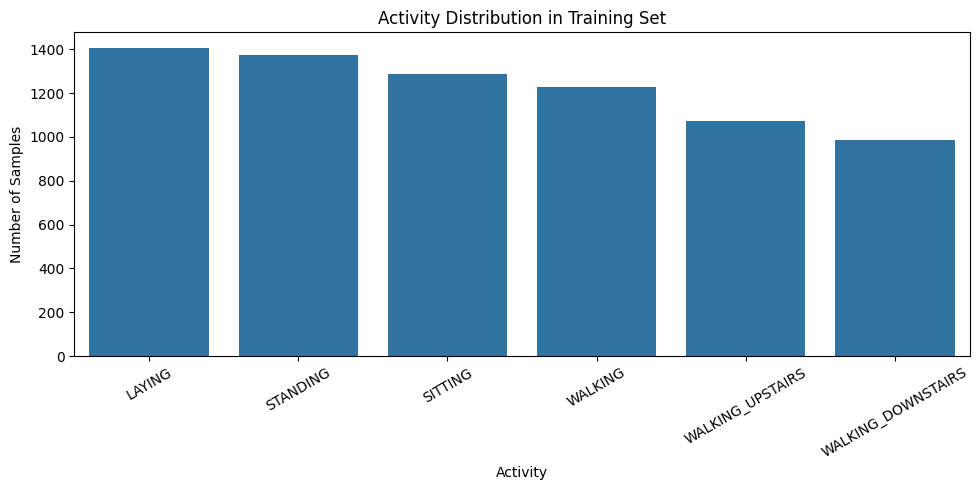

In [17]:
# Visualize activity distribution

plt.figure(figsize=(10, 5))

sns.countplot(
    data=y_train,
    x="activity_name",
    order=train_activity_counts.index
)

plt.title("Activity Distribution in Training Set")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
# Check feature data types and value ranges

print("Data types:")
print(X_train.dtypes.value_counts())

print("\nMinimum feature value:", X_train.min().min())
print("Maximum feature value:", X_train.max().max())

print("\nNumber of features:", X_train.shape[1])

Data types:
float64    561
Name: count, dtype: int64

Minimum feature value: -1.0
Maximum feature value: 1.0

Number of features: 561


In [19]:
# Check for identical samples between training and testing sets

train_array = X_train.to_numpy()
test_array = X_test.to_numpy()

# Convert each sample into a tuple
train_samples = set(map(tuple, train_array))
test_samples = set(map(tuple, test_array))

overlap = train_samples.intersection(test_samples)

print("Number of identical samples shared between train and test:")
print(len(overlap))

Number of identical samples shared between train and test:
0


In [20]:
# Prepare target labels for machine learning models

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train[0])
y_test_encoded = label_encoder.transform(y_test[0])

print("Encoded class mapping:")

for encoded_label, original_label in enumerate(label_encoder.classes_):
    activity_name = activity_map[original_label]
    print(f"{original_label} -> {encoded_label} -> {activity_name}")

Encoded class mapping:
1 -> 0 -> WALKING
2 -> 1 -> WALKING_UPSTAIRS
3 -> 2 -> WALKING_DOWNSTAIRS
4 -> 3 -> SITTING
5 -> 4 -> STANDING
6 -> 5 -> LAYING


In [21]:
# Split the training data into training and validation sets

from sklearn.model_selection import train_test_split

X_train_sub_raw, X_val_raw, y_train_sub, y_val = train_test_split(
    X_train,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)

print("Training subset shape:", X_train_sub_raw.shape)
print("Validation set shape :", X_val_raw.shape)
print("Test set shape       :", X_test.shape)

print("\nLabel shapes:")
print("y_train_sub:", y_train_sub.shape)
print("y_val     :", y_val.shape)
print("y_test    :", y_test_encoded.shape)

Training subset shape: (5881, 561)
Validation set shape : (1471, 561)
Test set shape       : (2947, 561)

Label shapes:
y_train_sub: (5881,)
y_val     : (1471,)
y_test    : (2947,)


In [22]:
# Standardize the features without data leakage

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit the scaler ONLY on the training subset
X_train_scaled = scaler.fit_transform(X_train_sub_raw)

# Transform validation and test sets using the same scaler
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test)

print("Standardization completed!")
print()
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_val_scaled shape  :", X_val_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

print("\nFirst feature after standardization:")
print("Mean:", X_train_scaled[:, 0].mean())
print("Std :", X_train_scaled[:, 0].std())

Standardization completed!

X_train_scaled shape: (5881, 561)
X_val_scaled shape  : (1471, 561)
X_test_scaled shape : (2947, 561)

First feature after standardization:
Mean: 1.347143598660962e-16
Std : 0.9999999999999998


In [23]:
# Train Logistic Regression baseline

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train_sub
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [24]:
# Evaluate Logistic Regression on the validation set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_val_pred_logistic = logistic_model.predict(X_val_scaled)

logistic_val_accuracy = accuracy_score(
    y_val, y_val_pred_logistic
)

logistic_val_precision = precision_score(
    y_val, y_val_pred_logistic, average="macro"
)

logistic_val_recall = recall_score(
    y_val, y_val_pred_logistic, average="macro"
)

logistic_val_f1 = f1_score(
    y_val, y_val_pred_logistic, average="macro"
)

print("Logistic Regression - Validation Results")
print("=" * 45)
print(f"Accuracy : {logistic_val_accuracy:.4f}")
print(f"Precision: {logistic_val_precision:.4f}")
print(f"Recall   : {logistic_val_recall:.4f}")
print(f"Macro F1 : {logistic_val_f1:.4f}")

Logistic Regression - Validation Results
Accuracy : 0.9803
Precision: 0.9819
Recall   : 0.9817
Macro F1 : 0.9818


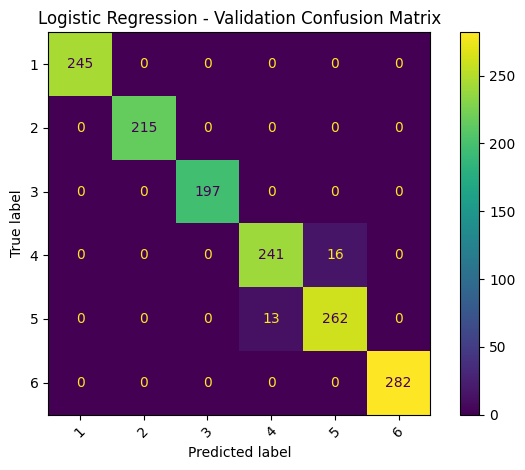

In [25]:
# Plot confusion matrix for Logistic Regression

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_logistic = confusion_matrix(
    y_val,
    y_val_pred_logistic
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [26]:
# Train Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train_sub)

print("Random Forest training completed.")

Random Forest training completed.


In [27]:
# Evaluate Random Forest on the validation set

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_val_pred_rf = rf_model.predict(X_val_scaled)

rf_accuracy = accuracy_score(y_val, y_val_pred_rf)
rf_precision = precision_score(y_val, y_val_pred_rf, average="macro")
rf_recall = recall_score(y_val, y_val_pred_rf, average="macro")
rf_f1 = f1_score(y_val, y_val_pred_rf, average="macro")

print("Random Forest - Validation Results")
print("=" * 40)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"Macro F1 : {rf_f1:.4f}")

Random Forest - Validation Results
Accuracy : 0.9803
Precision: 0.9806
Recall   : 0.9804
Macro F1 : 0.9804


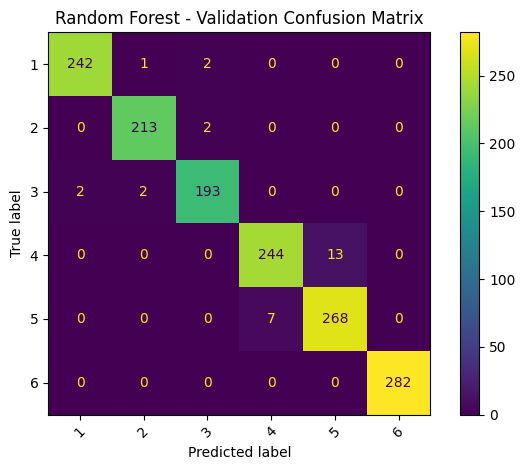

In [28]:
# Plot confusion matrix for Random Forest

cm_rf = confusion_matrix(
    y_val,
    y_val_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("Random Forest - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
# Train SVM

from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train_sub)

print("SVM training completed.")

SVM training completed.


In [30]:
# Evaluate SVM on the validation set

y_val_pred_svm = svm_model.predict(X_val_scaled)

svm_accuracy = accuracy_score(y_val, y_val_pred_svm)
svm_precision = precision_score(y_val, y_val_pred_svm, average="macro")
svm_recall = recall_score(y_val, y_val_pred_svm, average="macro")
svm_f1 = f1_score(y_val, y_val_pred_svm, average="macro")

print("SVM - Validation Results")
print("=" * 40)
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"Macro F1 : {svm_f1:.4f}")

SVM - Validation Results
Accuracy : 0.9823
Precision: 0.9835
Recall   : 0.9837
Macro F1 : 0.9836


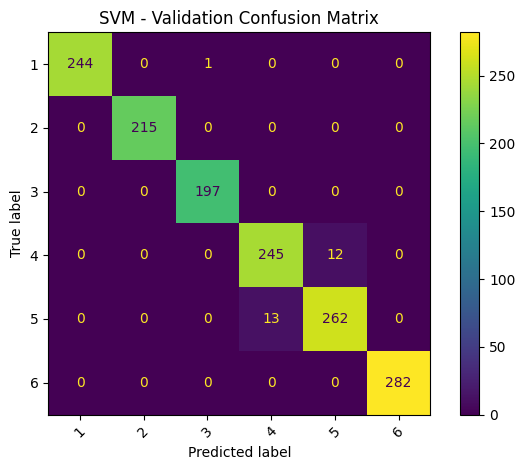

In [31]:
# Plot confusion matrix for SVM

cm_svm = confusion_matrix(
    y_val,
    y_val_pred_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("SVM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [32]:
# PyTorch setup

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [33]:
# Convert data to PyTorch tensors

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_sub,
    dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

# Create datasets
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

print("Tensor and DataLoader setup completed.")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Batch size:", 64)

Tensor and DataLoader setup completed.
Training samples: 5881
Validation samples: 1471
Batch size: 64


In [34]:
# Define our MLP model

class MLP_HAR(nn.Module):
    def __init__(self):
        super(MLP_HAR, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(561, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 6)
        )

    def forward(self, x):
        return self.network(x)


# Create model and move it to GPU
mlp_model = MLP_HAR().to(device)

print(mlp_model)

MLP_HAR(
  (network): Sequential(
    (0): Linear(in_features=561, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=6, bias=True)
  )
)


In [35]:
# Define loss function, optimizer, and learning rate scheduler

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Initial learning rate: 0.001


In [36]:
# Train the MLP model

num_epochs = 50

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    mlp_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = mlp_model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        _, predicted = torch.max(outputs, 1)
        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -------------------------
    # Validation
    # -------------------------
    mlp_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = mlp_model(X_batch)
            loss = criterion(outputs, y_batch)

            val_running_loss += loss.item() * X_batch.size(0)

            _, predicted = torch.max(outputs, 1)
            val_total += y_batch.size(0)
            val_correct += (predicted == y_batch).sum().item()

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # Save history
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Update learning rate
    scheduler.step(val_loss)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = mlp_model.state_dict()

    # Print every epoch
    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# Restore best model
mlp_model.load_state_dict(best_model_state)

print("\nTraining completed.")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [01/50] Train Loss: 0.4826 | Train Acc: 0.8060 | Val Loss: 0.1581 | Val Acc: 0.9279
Epoch [02/50] Train Loss: 0.1499 | Train Acc: 0.9424 | Val Loss: 0.0871 | Val Acc: 0.9667
Epoch [03/50] Train Loss: 0.1055 | Train Acc: 0.9604 | Val Loss: 0.0858 | Val Acc: 0.9667
Epoch [04/50] Train Loss: 0.0748 | Train Acc: 0.9704 | Val Loss: 0.0785 | Val Acc: 0.9667
Epoch [05/50] Train Loss: 0.0737 | Train Acc: 0.9731 | Val Loss: 0.0556 | Val Acc: 0.9742
Epoch [06/50] Train Loss: 0.0795 | Train Acc: 0.9694 | Val Loss: 0.0858 | Val Acc: 0.9633
Epoch [07/50] Train Loss: 0.0689 | Train Acc: 0.9743 | Val Loss: 0.0660 | Val Acc: 0.9728
Epoch [08/50] Train Loss: 0.0536 | Train Acc: 0.9798 | Val Loss: 0.0556 | Val Acc: 0.9755
Epoch [09/50] Train Loss: 0.0449 | Train Acc: 0.9830 | Val Loss: 0.1037 | Val Acc: 0.9619
Epoch [10/50] Train Loss: 0.0461 | Train Acc: 0.9830 | Val Loss: 0.0600 | Val Acc: 0.9762
Epoch [11/50] Train Loss: 0.0391 | Train Acc: 0.9852 | Val Loss: 0.0755 | Val Acc: 0.9708
Epoch [12/

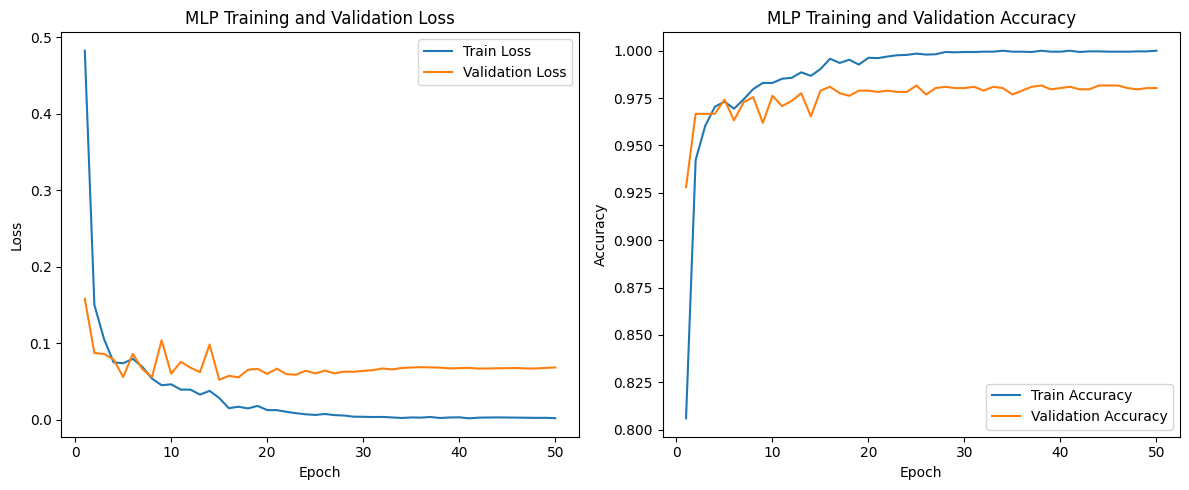

In [37]:
# Plot MLP training history

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
# Evaluate the best MLP model on the validation set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

mlp_model.eval()

y_val_pred_mlp = []
y_val_true_mlp = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        outputs = mlp_model(X_batch)
        predictions = torch.argmax(outputs, dim=1)

        y_val_pred_mlp.extend(predictions.cpu().numpy())
        y_val_true_mlp.extend(y_batch.numpy())

y_val_pred_mlp = np.array(y_val_pred_mlp)
y_val_true_mlp = np.array(y_val_true_mlp)

mlp_accuracy = accuracy_score(y_val_true_mlp, y_val_pred_mlp)
mlp_precision = precision_score(
    y_val_true_mlp,
    y_val_pred_mlp,
    average="macro"
)
mlp_recall = recall_score(
    y_val_true_mlp,
    y_val_pred_mlp,
    average="macro"
)
mlp_f1 = f1_score(
    y_val_true_mlp,
    y_val_pred_mlp,
    average="macro"
)

print("MLP - Validation Results")
print("=" * 40)
print(f"Accuracy : {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall   : {mlp_recall:.4f}")
print(f"Macro F1 : {mlp_f1:.4f}")

MLP - Validation Results
Accuracy : 0.9803
Precision: 0.9819
Recall   : 0.9817
Macro F1 : 0.9818


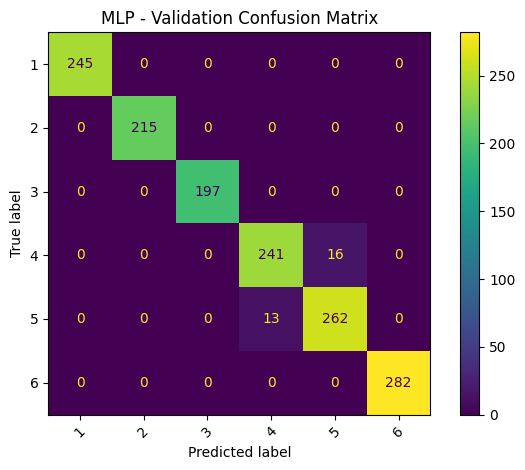

In [39]:
# Plot confusion matrix for MLP

cm_mlp = confusion_matrix(
    y_val_true_mlp,
    y_val_pred_mlp
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("MLP - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [40]:
# Compare all models on the validation set

validation_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "MLP"
    ],
    "Accuracy": [
        0.9803,
        0.9803,
        0.9823,
        mlp_accuracy
    ],
    "Precision": [
        0.9819,
        0.9806,
        0.9835,
        mlp_precision
    ],
    "Recall": [
        0.9817,
        0.9804,
        0.9837,
        mlp_recall
    ],
    "Macro F1": [
        0.9818,
        0.9804,
        0.9836,
        mlp_f1
    ]
})

print("Validation Model Comparison")
print("=" * 60)

display(
    validation_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

Validation Model Comparison


,Model,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,0.9803,0.9819,0.9817,0.9818
1,Random Forest,0.9803,0.9806,0.9804,0.9804
2,SVM,0.9823,0.9835,0.9837,0.9836
3,MLP,0.9803,0.9819,0.9817,0.9818


In [41]:
# Generate predictions on the test set

# Logistic Regression
y_test_pred_logistic = logistic_model.predict(X_test_scaled)

# Random Forest
y_test_pred_rf = rf_model.predict(X_test_scaled)

# SVM
y_test_pred_svm = svm_model.predict(X_test_scaled)

# MLP
mlp_model.eval()

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
).to(device)

with torch.no_grad():
    outputs = mlp_model(X_test_tensor)
    y_test_pred_mlp = torch.argmax(outputs, dim=1).cpu().numpy()

print("Test predictions generated successfully.")
print("Test samples:", len(y_test))

Test predictions generated successfully.
Test samples: 2947


In [42]:
# Evaluate all models on the test set

test_results = []

models_predictions = {
    "Logistic Regression": y_test_pred_logistic,
    "Random Forest": y_test_pred_rf,
    "SVM": y_test_pred_svm,
    "MLP": y_test_pred_mlp
}

for model_name, predictions in models_predictions.items():

    accuracy = accuracy_score(
        y_test_encoded,
        predictions
    )

    precision = precision_score(
        y_test_encoded,
        predictions,
        average="macro"
    )

    recall = recall_score(
        y_test_encoded,
        predictions,
        average="macro"
    )

    f1 = f1_score(
        y_test_encoded,
        predictions,
        average="macro"
    )

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": f1
    })

test_results_df = pd.DataFrame(test_results)

print("Test Set Model Comparison")
print("=" * 60)

display(
    test_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

Test Set Model Comparison


,Model,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,0.9498,0.9534,0.9485,0.9497
1,Random Forest,0.9281,0.9292,0.9248,0.9261
2,SVM,0.9572,0.9582,0.9556,0.9564
3,MLP,0.9488,0.9518,0.9474,0.9486


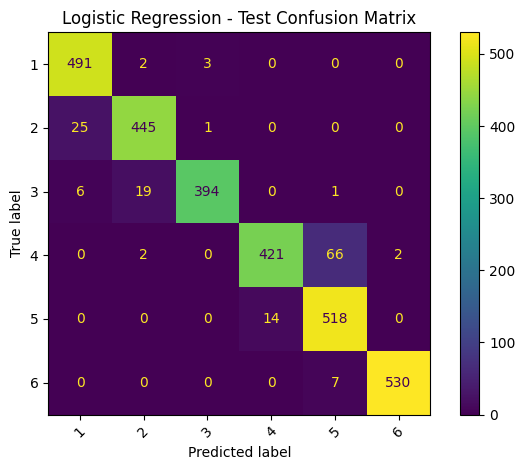

In [43]:
# Logistic Regression - Test Confusion Matrix

cm_logistic_test = confusion_matrix(
    y_test_encoded,
    y_test_pred_logistic
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic_test,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("Logistic Regression - Test Confusion Matrix")
plt.tight_layout()
plt.show()

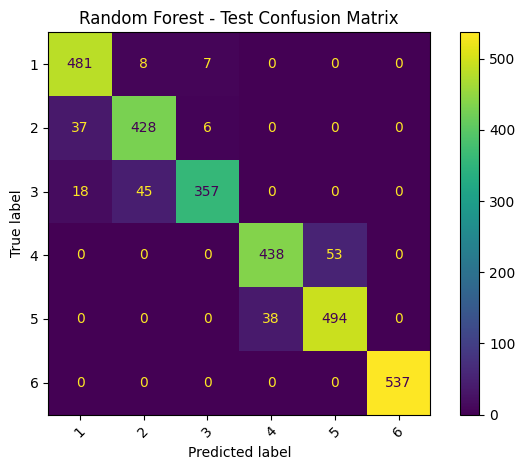

In [44]:
# Random Forest - Test Confusion Matrix

cm_rf_test = confusion_matrix(
    y_test_encoded,
    y_test_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_test,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.show()

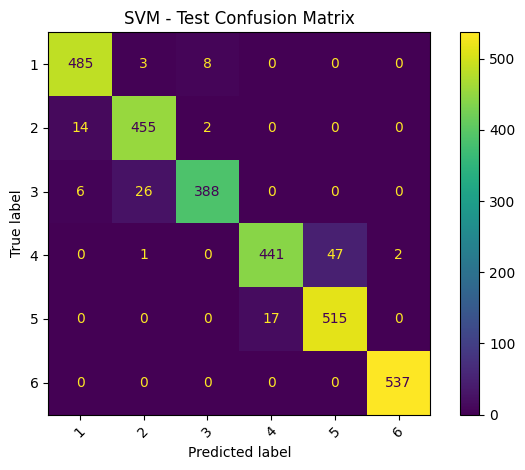

In [45]:
# SVM - Test Confusion Matrix

cm_svm_test = confusion_matrix(
    y_test_encoded,
    y_test_pred_svm
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_test,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("SVM - Test Confusion Matrix")
plt.tight_layout()
plt.show()

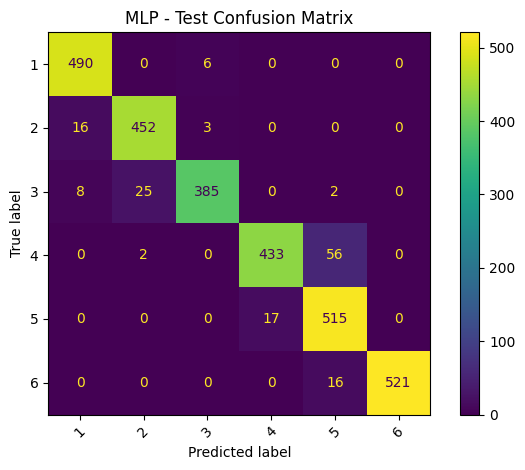

In [46]:
# MLP - Test Confusion Matrix

cm_mlp_test = confusion_matrix(
    y_test_encoded,
    y_test_pred_mlp
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp_test,
    display_labels=label_encoder.classes_
)

disp.plot(xticks_rotation=45)

plt.title("MLP - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [47]:
# Create final validation and test comparison table

final_comparison = validation_results.copy()

final_comparison = final_comparison.rename(columns={
    "Accuracy": "Validation Accuracy",
    "Precision": "Validation Precision",
    "Recall": "Validation Recall",
    "Macro F1": "Validation Macro F1"
})

final_comparison["Test Accuracy"] = test_results_df["Accuracy"]
final_comparison["Test Precision"] = test_results_df["Precision"]
final_comparison["Test Recall"] = test_results_df["Recall"]
final_comparison["Test Macro F1"] = test_results_df["Macro F1"]

print("FINAL MODEL COMPARISON")
print("=" * 100)

display(
    final_comparison.style.format({
        "Validation Accuracy": "{:.4f}",
        "Validation Precision": "{:.4f}",
        "Validation Recall": "{:.4f}",
        "Validation Macro F1": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Test Precision": "{:.4f}",
        "Test Recall": "{:.4f}",
        "Test Macro F1": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Validation Accuracy,Validation Precision,Validation Recall,Validation Macro F1,Test Accuracy,Test Precision,Test Recall,Test Macro F1
0,Logistic Regression,0.9803,0.9819,0.9817,0.9818,0.9498,0.9534,0.9485,0.9497
1,Random Forest,0.9803,0.9806,0.9804,0.9804,0.9281,0.9292,0.9248,0.9261
2,SVM,0.9823,0.9835,0.9837,0.9836,0.9572,0.9582,0.9556,0.9564
3,MLP,0.9803,0.9819,0.9817,0.9818,0.9488,0.9518,0.9474,0.9486


In [48]:
# Verify MLP test results

print("MLP TEST - FINAL VERIFICATION")
print("=" * 50)

print(f"Accuracy : {accuracy_score(y_test_encoded, y_test_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_test_encoded, y_test_pred_mlp, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test_encoded, y_test_pred_mlp, average='macro'):.4f}")
print(f"Macro F1 : {f1_score(y_test_encoded, y_test_pred_mlp, average='macro'):.4f}")

MLP TEST - FINAL VERIFICATION
Accuracy : 0.9488
Precision: 0.9518
Recall   : 0.9474
Macro F1 : 0.9486


In [49]:
# Save models, scaler, and label encoder to Google Drive

from google.colab import drive
import os
import joblib

# Mount Google Drive
drive.mount("/content/drive")

# Create project folders
project_dir = "/content/drive/MyDrive/Human_Activity_Recognition"

models_dir = os.path.join(project_dir, "models")
preprocessing_dir = os.path.join(project_dir, "preprocessing")
results_dir = os.path.join(project_dir, "results")

os.makedirs(models_dir, exist_ok=True)
os.makedirs(preprocessing_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Save traditional machine learning models
joblib.dump(
    logistic_model,
    os.path.join(models_dir, "logistic_regression.joblib")
)

joblib.dump(
    rf_model,
    os.path.join(models_dir, "random_forest.joblib")
)

joblib.dump(
    svm_model,
    os.path.join(models_dir, "svm.joblib")
)

# Save MLP model
torch.save(
    mlp_model.state_dict(),
    os.path.join(models_dir, "mlp_har.pth")
)

# Save preprocessing objects
joblib.dump(
    scaler,
    os.path.join(preprocessing_dir, "scaler.joblib")
)

joblib.dump(
    label_encoder,
    os.path.join(preprocessing_dir, "label_encoder.joblib")
)

print("Models and preprocessing objects saved successfully!")
print("\nProject directory:")
print(project_dir)

print("\nModels:")
for file in os.listdir(models_dir):
    print("-", file)

print("\nPreprocessing:")
for file in os.listdir(preprocessing_dir):
    print("-", file)

Mounted at /content/drive
Models and preprocessing objects saved successfully!

Project directory:
/content/drive/MyDrive/Human_Activity_Recognition

Models:
- logistic_regression.joblib
- random_forest.joblib
- svm.joblib
- mlp_har.pth

Preprocessing:
- scaler.joblib
- label_encoder.joblib


In [50]:
# Save validation results, test results, final comparison,
# and MLP training history

# 1. Validation results
validation_results.to_csv(
    os.path.join(results_dir, "validation_results.csv"),
    index=False
)

# 2. Test results
test_results_df.to_csv(
    os.path.join(results_dir, "test_results.csv"),
    index=False
)

# 3. Final comparison
final_comparison.to_csv(
    os.path.join(results_dir, "final_comparison.csv"),
    index=False
)

# 4. MLP training history
training_history = pd.DataFrame({
    "Epoch": range(1, num_epochs + 1),
    "Train_Loss": train_losses,
    "Validation_Loss": val_losses,
    "Train_Accuracy": train_accuracies,
    "Validation_Accuracy": val_accuracies
})

training_history.to_csv(
    os.path.join(results_dir, "mlp_training_history.csv"),
    index=False
)

print("All results saved successfully!")

print("\nResults files:")
for file in os.listdir(results_dir):
    print("-", file)

All results saved successfully!

Results files:
- validation_results.csv
- test_results.csv
- final_comparison.csv
- mlp_training_history.csv


In [51]:
# Save MLP architecture and training information

mlp_info = {
    "input_features": 561,
    "hidden_layer_1": 256,
    "hidden_layer_2": 128,
    "output_classes": 6,
    "dropout": 0.3,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 64,
    "epochs": 50,
    "best_validation_loss": best_val_loss,
    "device": str(device)
}

mlp_info_df = pd.DataFrame(
    list(mlp_info.items()),
    columns=["Parameter", "Value"]
)

mlp_info_df.to_csv(
    os.path.join(results_dir, "mlp_training_config.csv"),
    index=False
)

print("MLP training configuration saved successfully!")
print("\nConfiguration:")
display(mlp_info_df)

MLP training configuration saved successfully!

Configuration:


,Parameter,Value
0,input_features,561
1,hidden_layer_1,256
2,hidden_layer_2,128
3,output_classes,6
4,dropout,0.3
5,optimizer,Adam
6,learning_rate,0.001
7,weight_decay,0.0001
8,batch_size,64
9,epochs,50


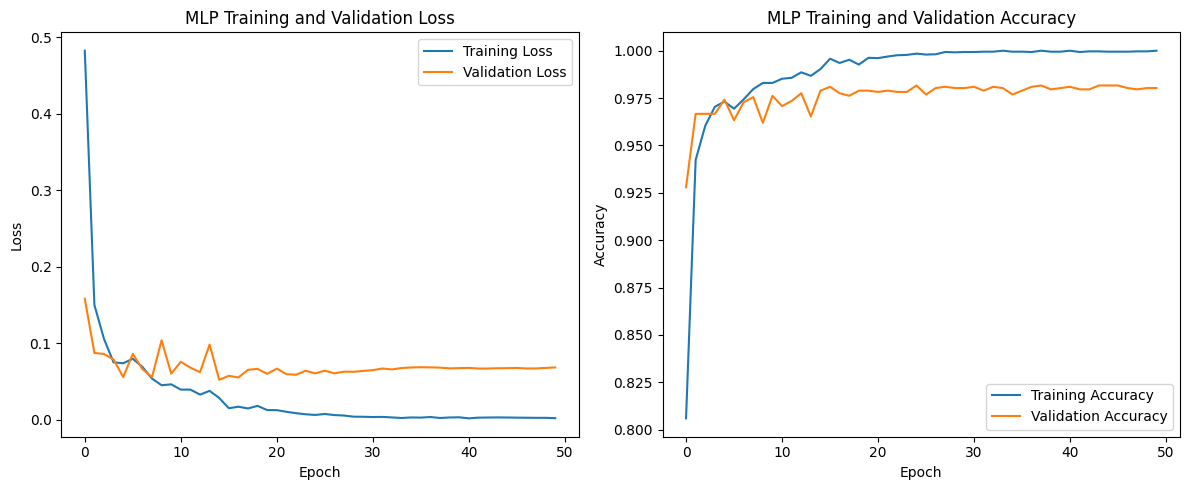

Training curves saved successfully!
/content/drive/MyDrive/Human_Activity_Recognition/results/mlp_training_curves.png


In [52]:
# Save MLP training curves to Google Drive

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")
plt.legend()

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.legend()

plt.tight_layout()

training_curve_path = os.path.join(
    results_dir,
    "mlp_training_curves.png"
)

plt.savefig(training_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("Training curves saved successfully!")
print(training_curve_path)

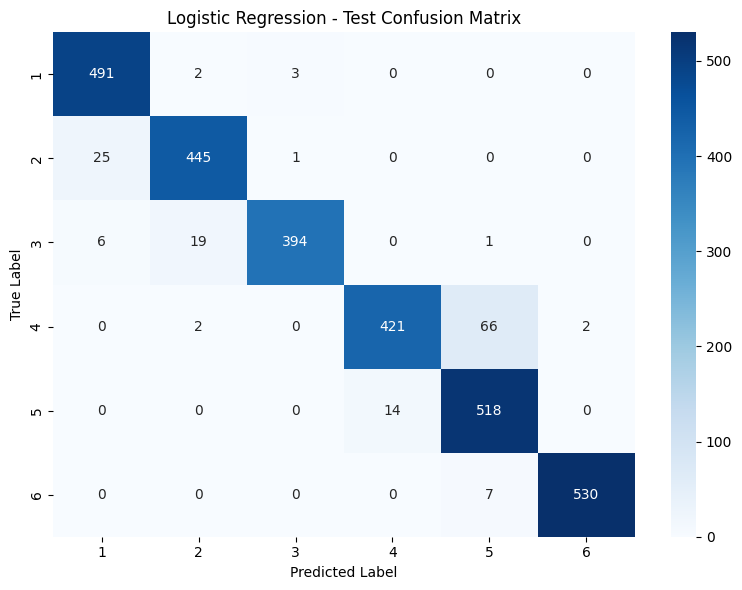

Saved: /content/drive/MyDrive/Human_Activity_Recognition/results/logistic_regression_confusion_matrix.png


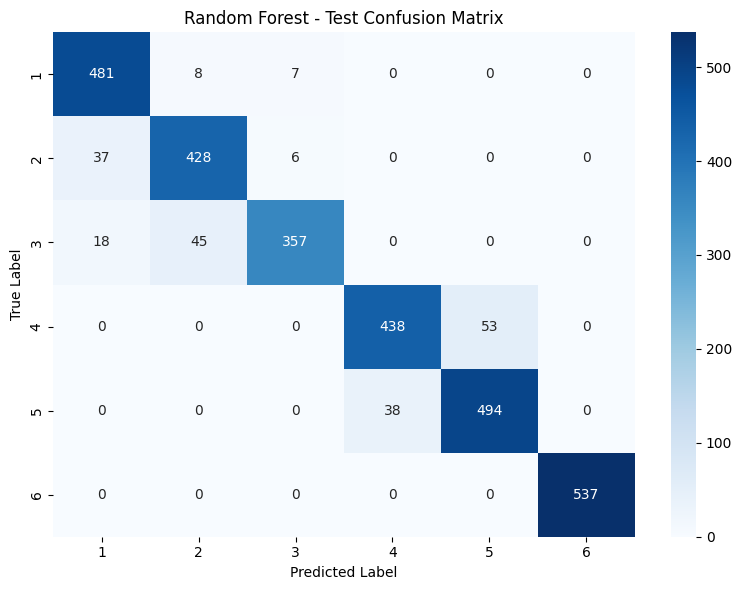

Saved: /content/drive/MyDrive/Human_Activity_Recognition/results/random_forest_confusion_matrix.png


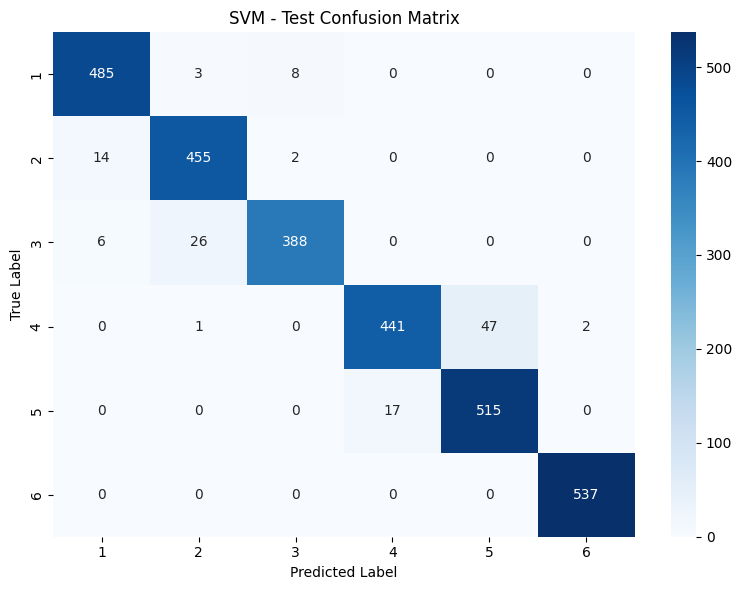

Saved: /content/drive/MyDrive/Human_Activity_Recognition/results/svm_confusion_matrix.png


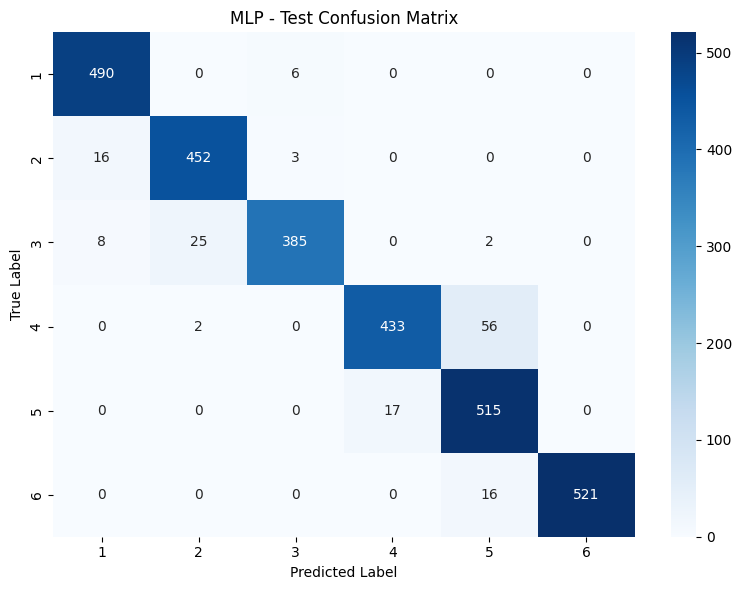

Saved: /content/drive/MyDrive/Human_Activity_Recognition/results/mlp_confusion_matrix.png

All confusion matrices saved successfully!


In [53]:
# Save confusion matrices for all models

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Predictions on test set
logistic_test_pred = logistic_model.predict(X_test_scaled)
rf_test_pred = rf_model.predict(X_test_scaled)
svm_test_pred = svm_model.predict(X_test_scaled)

mlp_model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(
        X_test_scaled,
        dtype=torch.float32
    ).to(device)

    mlp_outputs = mlp_model(X_test_tensor)
    mlp_test_pred = torch.argmax(mlp_outputs, dim=1).cpu().numpy()

# Model predictions
predictions = {
    "Logistic Regression": logistic_test_pred,
    "Random Forest": rf_test_pred,
    "SVM": svm_test_pred,
    "MLP": mlp_test_pred
}

# Save each confusion matrix
for model_name, y_pred in predictions.items():

    cm = confusion_matrix(y_test_encoded, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()

    filename = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "")
        + "_confusion_matrix.png"
    )

    save_path = os.path.join(results_dir, filename)

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(f"Saved: {save_path}")

print("\nAll confusion matrices saved successfully!")

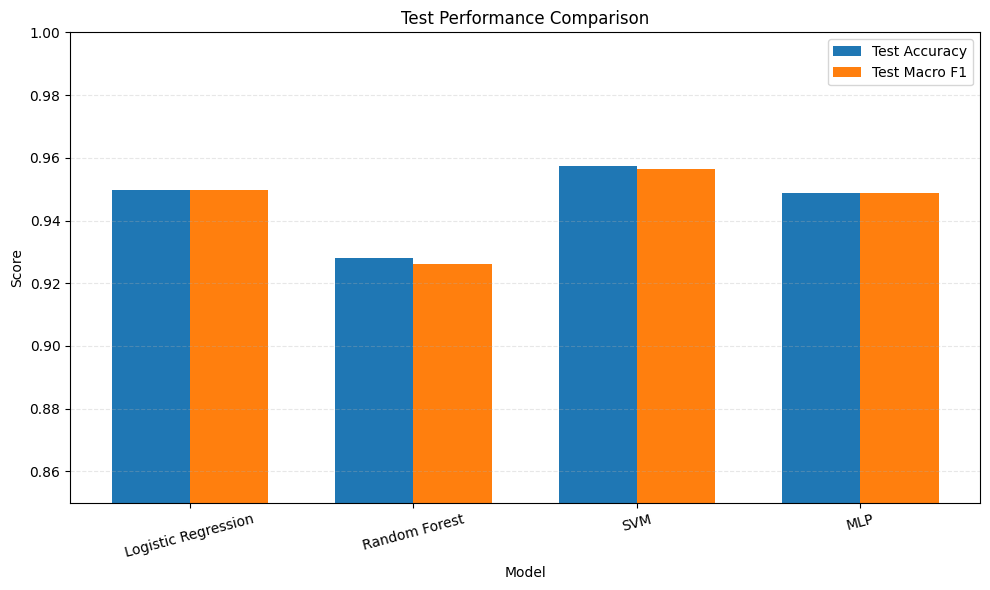

Model comparison chart saved successfully!
/content/drive/MyDrive/Human_Activity_Recognition/results/test_model_comparison.png


In [54]:
# Create and save model comparison chart

import matplotlib.pyplot as plt
import numpy as np

models = final_comparison["Model"]

test_accuracy = final_comparison["Test Accuracy"]
test_macro_f1 = final_comparison["Test Macro F1"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    test_accuracy,
    width,
    label="Test Accuracy"
)

plt.bar(
    x + width / 2,
    test_macro_f1,
    width,
    label="Test Macro F1"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Test Performance Comparison")

plt.xticks(x, models, rotation=15)
plt.ylim(0.85, 1.00)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

comparison_chart_path = os.path.join(
    results_dir,
    "test_model_comparison.png"
)

plt.savefig(
    comparison_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")
print(comparison_chart_path)

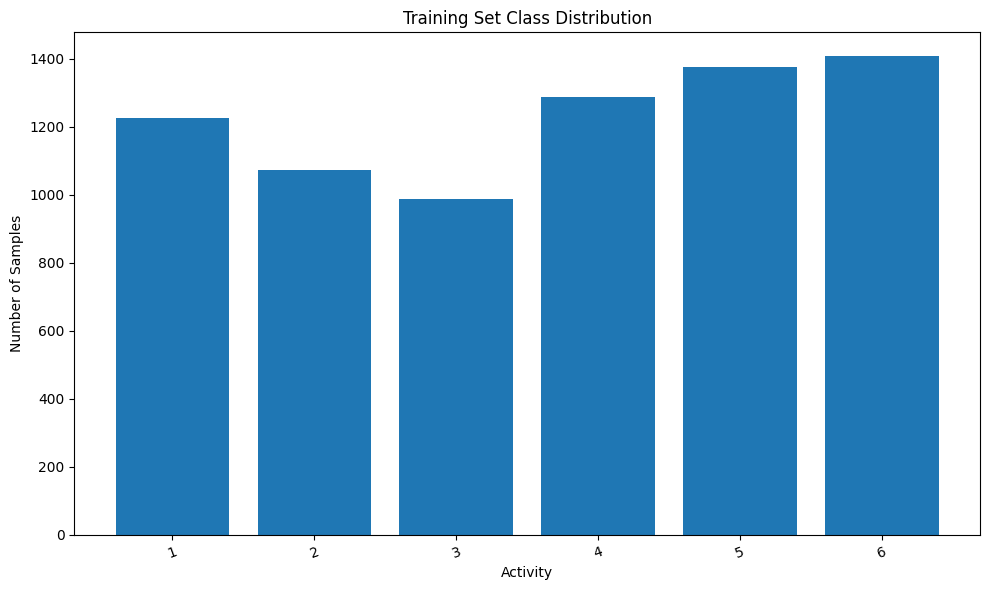

Class distribution chart saved successfully!
/content/drive/MyDrive/Human_Activity_Recognition/results/class_distribution.png


In [55]:
# Save activity class distribution chart

import matplotlib.pyplot as plt
import os

# Count training samples for each activity
train_class_counts = pd.Series(y_train_encoded).value_counts().sort_index()

activity_names = label_encoder.inverse_transform(
    train_class_counts.index
)

plt.figure(figsize=(10, 6))

plt.bar(
    activity_names,
    train_class_counts.values
)

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("Training Set Class Distribution")

plt.xticks(rotation=20)

plt.tight_layout()

class_distribution_path = os.path.join(
    results_dir,
    "class_distribution.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart saved successfully!")
print(class_distribution_path)

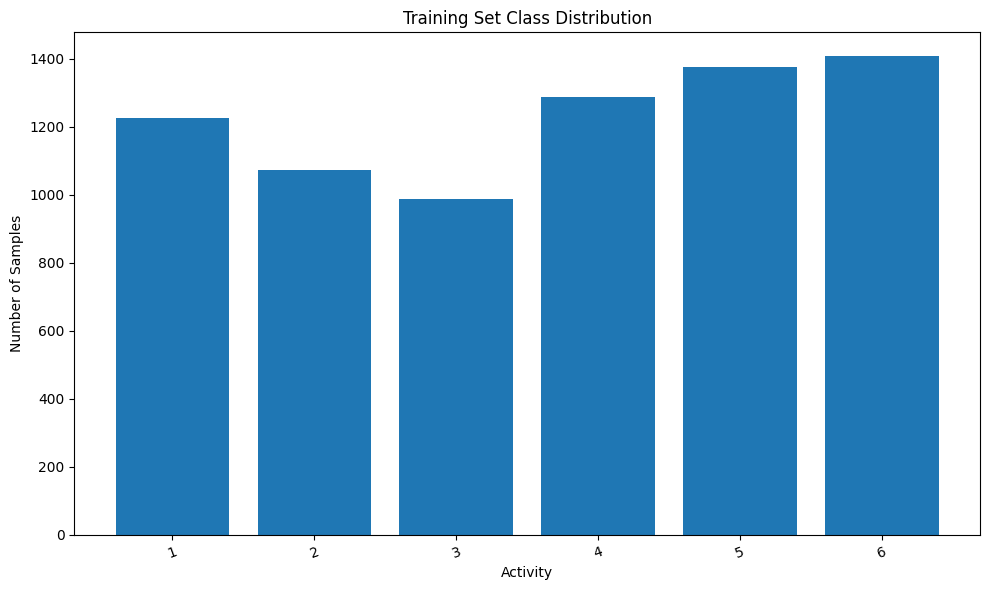

Class distribution chart updated successfully!
/content/drive/MyDrive/Human_Activity_Recognition/results/class_distribution.png


In [56]:
# Create a clearer class distribution chart with activity names

import matplotlib.pyplot as plt
import os

# Count training samples for each encoded class
train_class_counts = pd.Series(
    y_train_encoded
).value_counts().sort_index()

# Convert encoded labels to activity names
activity_names = label_encoder.inverse_transform(
    train_class_counts.index
)

plt.figure(figsize=(10, 6))

plt.bar(
    activity_names,
    train_class_counts.values
)

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("Training Set Class Distribution")

plt.xticks(rotation=20)

plt.tight_layout()

class_distribution_path = os.path.join(
    results_dir,
    "class_distribution.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart updated successfully!")
print(class_distribution_path)

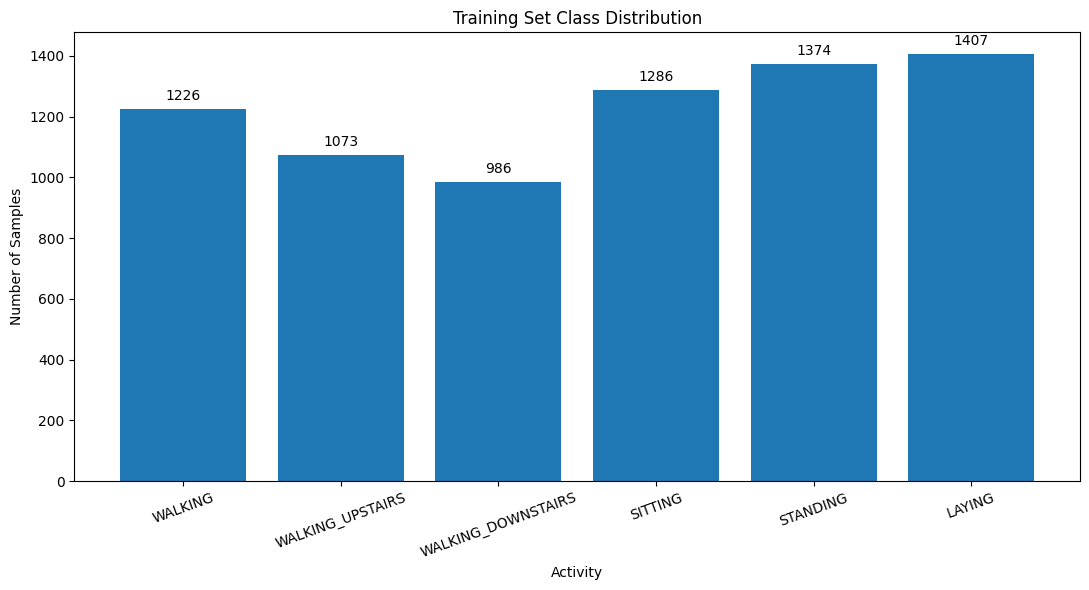

Class distribution chart fixed successfully!
/content/drive/MyDrive/Human_Activity_Recognition/results/class_distribution.png


In [57]:
# Fix activity names on the class distribution chart

import matplotlib.pyplot as plt
import os

# Class names in the original UCI HAR dataset
activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

# Count samples for the 6 classes
class_counts = [
    (y_train.iloc[:, 0] == 1).sum(),
    (y_train.iloc[:, 0] == 2).sum(),
    (y_train.iloc[:, 0] == 3).sum(),
    (y_train.iloc[:, 0] == 4).sum(),
    (y_train.iloc[:, 0] == 5).sum(),
    (y_train.iloc[:, 0] == 6).sum()
]

plt.figure(figsize=(11, 6))

bars = plt.bar(
    range(6),
    class_counts
)

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("Training Set Class Distribution")

# Use activity names instead of numeric labels
plt.xticks(
    range(6),
    activity_names,
    rotation=20
)

# Add sample counts above each bar
for bar, count in zip(bars, class_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

class_distribution_path = os.path.join(
    results_dir,
    "class_distribution.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart fixed successfully!")
print(class_distribution_path)

In [58]:
# Check all saved project results

import os

print("=" * 60)
print("SAVED RESULTS")
print("=" * 60)

for root, dirs, files in os.walk(results_dir):
    for file in sorted(files):
        file_path = os.path.join(root, file)
        file_size = os.path.getsize(file_path) / 1024

        print(f"{file:<45} {file_size:>8.1f} KB")

print("\nResults directory:")
print(results_dir)

SAVED RESULTS
class_distribution.png                           185.3 KB
final_comparison.csv                               0.6 KB
logistic_regression_confusion_matrix.png         110.5 KB
mlp_confusion_matrix.png                         105.5 KB
mlp_training_config.csv                            0.2 KB
mlp_training_curves.png                          223.5 KB
mlp_training_history.csv                           4.0 KB
random_forest_confusion_matrix.png               109.8 KB
svm_confusion_matrix.png                         104.0 KB
test_model_comparison.png                        142.0 KB
test_results.csv                                   0.4 KB
validation_results.csv                             0.2 KB

Results directory:
/content/drive/MyDrive/Human_Activity_Recognition/results


In [59]:
# Create GitHub-ready project structure

import os
import shutil

github_dir = "/content/drive/MyDrive/Human_Activity_Recognition_GitHub"

# Create project folders
folders = [
    "data",
    "notebooks",
    "src",
    "models",
    "preprocessing",
    "results"
]

for folder in folders:
    os.makedirs(
        os.path.join(github_dir, folder),
        exist_ok=True
    )

# Copy trained models
for file in os.listdir(models_dir):
    source = os.path.join(models_dir, file)
    destination = os.path.join(github_dir, "models", file)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

# Copy preprocessing objects
for file in os.listdir(preprocessing_dir):
    source = os.path.join(preprocessing_dir, file)
    destination = os.path.join(github_dir, "preprocessing", file)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

# Copy all results
for file in os.listdir(results_dir):
    source = os.path.join(results_dir, file)
    destination = os.path.join(github_dir, "results", file)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

print("=" * 60)
print("GITHUB PROJECT STRUCTURE CREATED")
print("=" * 60)

print(f"\nProject directory:")
print(github_dir)

print("\nFolders:")
for folder in folders:
    print(f"- {folder}/")

print("\nModels copied:")
for file in os.listdir(os.path.join(github_dir, "models")):
    print(f"- {file}")

print("\nResults copied:")
for file in sorted(os.listdir(os.path.join(github_dir, "results"))):
    print(f"- {file}")

print("\nProject structure is ready!")

GITHUB PROJECT STRUCTURE CREATED

Project directory:
/content/drive/MyDrive/Human_Activity_Recognition_GitHub

Folders:
- data/
- notebooks/
- src/
- models/
- preprocessing/
- results/

Models copied:
- logistic_regression.joblib
- random_forest.joblib
- svm.joblib
- mlp_har.pth

Results copied:
- class_distribution.png
- final_comparison.csv
- logistic_regression_confusion_matrix.png
- mlp_confusion_matrix.png
- mlp_training_config.csv
- mlp_training_curves.png
- mlp_training_history.csv
- random_forest_confusion_matrix.png
- svm_confusion_matrix.png
- test_model_comparison.png
- test_results.csv
- validation_results.csv

Project structure is ready!


In [61]:
%%writefile /content/drive/MyDrive/Human_Activity_Recognition_GitHub/README.md

# Human Activity Recognition Using Smartphone Sensor Data

## 1. Project Overview

This project focuses on Human Activity Recognition (HAR) using smartphone sensor data.

The goal is to classify human activities into six different classes based on sensor measurements collected from smartphones.

### Activities

1. WALKING
2. WALKING_UPSTAIRS
3. WALKING_DOWNSTAIRS
4. SITTING
5. STANDING
6. LAYING

The project uses the UCI Human Activity Recognition Using Smartphones Dataset.

---

## 2. Dataset

The dataset contains:

- 10,299 total samples
- 561 sensor features
- 6 activity classes
- 7,352 training samples
- 2,947 test samples

The raw dataset is not included in this repository.

---

## 3. Project Workflow

```text
Raw Smartphone Sensor Data
        ↓
Data Loading
        ↓
Data Inspection
        ↓
Data Preprocessing
        ↓
Train / Validation Split
        ↓
Feature Standardization
        ↓
Baseline Models
        ↓
Our MLP Model
        ↓
Model Evaluation
        ↓
Model Comparison
        ↓
Final Analysis

Writing /content/drive/MyDrive/Human_Activity_Recognition_GitHub/README.md


In [62]:
%%writefile /content/drive/MyDrive/Human_Activity_Recognition_GitHub/requirements.txt

numpy
pandas
scikit-learn
matplotlib
seaborn
joblib
torch
torchvision

Writing /content/drive/MyDrive/Human_Activity_Recognition_GitHub/requirements.txt


In [63]:
%%writefile /content/drive/MyDrive/Human_Activity_Recognition_GitHub/data/README.md

# Dataset

This project uses the **UCI Human Activity Recognition Using Smartphones Dataset**.

## Dataset Information

The dataset contains smartphone sensor measurements collected from participants performing six activities:

1. WALKING
2. WALKING_UPSTAIRS
3. WALKING_DOWNSTAIRS
4. SITTING
5. STANDING
6. LAYING

Dataset size:

- Total samples: 10,299
- Training samples: 7,352
- Test samples: 2,947
- Features: 561
- Classes: 6

## Download

The original dataset can be downloaded from the UCI Machine Learning Repository:

https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

## Repository Policy

The raw dataset is not included in this GitHub repository.

Users should download the original dataset from UCI and place it in the appropriate `data/` directory before running the notebooks.

## Dataset Structure

After downloading and extracting the dataset, the structure should contain:

```text
UCI HAR Dataset/
├── activity_labels.txt
├── features.txt
├── features_info.txt
├── README.txt
├── train/
└── test/

Writing /content/drive/MyDrive/Human_Activity_Recognition_GitHub/data/README.md


In [64]:
# Check the complete GitHub-ready project structure

import os

print("=" * 70)
print("GITHUB PROJECT STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(github_dir):
    level = root.replace(github_dir, "").count(os.sep)
    indent = "    " * level
    folder_name = os.path.basename(root)

    print(f"{indent}{folder_name}/")

    for file in sorted(files):
        print(f"{indent}    └── {file}")

print("\nProject path:")
print(github_dir)

GITHUB PROJECT STRUCTURE
Human_Activity_Recognition_GitHub/
    └── README.md
    └── requirements.txt
    data/
        └── README.md
    notebooks/
    src/
    models/
        └── logistic_regression.joblib
        └── mlp_har.pth
        └── random_forest.joblib
        └── svm.joblib
    preprocessing/
        └── label_encoder.joblib
        └── scaler.joblib
    results/
        └── class_distribution.png
        └── final_comparison.csv
        └── logistic_regression_confusion_matrix.png
        └── mlp_confusion_matrix.png
        └── mlp_training_config.csv
        └── mlp_training_curves.png
        └── mlp_training_history.csv
        └── random_forest_confusion_matrix.png
        └── svm_confusion_matrix.png
        └── test_model_comparison.png
        └── test_results.csv
        └── validation_results.csv

Project path:
/content/drive/MyDrive/Human_Activity_Recognition_GitHub


In [65]:
# Find the existing Human Activity Recognition notebook

import os
import shutil

notebook_name = "Human_Activity_Recognition.ipynb"

possible_paths = [
    f"/content/{notebook_name}",
    f"/content/drive/MyDrive/{notebook_name}",
    f"/content/drive/MyDrive/Human_Activity_Recognition/{notebook_name}"
]

found_path = None

for path in possible_paths:
    if os.path.exists(path):
        found_path = path
        break

if found_path is None:
    print("Notebook was not found in the expected locations.")
    print("\nPlease check your Google Drive location.")
else:
    destination = os.path.join(
        github_dir,
        "notebooks",
        notebook_name
    )

    shutil.copy2(found_path, destination)

    print("Notebook copied successfully!")
    print(f"\nFrom:")
    print(found_path)
    print(f"\nTo:")
    print(destination)

Notebook was not found in the expected locations.

Please check your Google Drive location.


In [ ]:
# Search Google Drive for the notebook

import os

search_name = "Human_Activity_Recognition.ipynb"
matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == search_name:
            matches.append(os.path.join(root, file))

print("=" * 60)
print("SEARCH RESULTS")
print("=" * 60)

if matches:
    for path in matches:
        print(path)
else:
    print("Notebook was not found in Google Drive.")